# Simulation 19: Heuristics vs. Baselines

TJ Kim
3/24/22

Run the second simulation with the following considerations.

- 10 Servers, 20 TS, 15 Users --> increase servers to 20 and users to 40
- Use ONE-mobility --> crawdad
- Job lengths: vr = 10-15, Assist = 5-10, AR = 10-15
- We share the same users and jobs between simulations

Resources: Normal
- All jobs are run with standard Quantity
- 14 level 1, 5 level 2, 1 level 3

In [46]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random
import matplotlib
import matplotlib.pyplot as plt

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim19")
sys.path.append(os.path.pardir+"/crawdad_mobility")



from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim19_setting import *
from load_crawdad_usr import *

# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [2]:
# Load Crawdad data
# Load All 12 users and trim their info
db_names = []
for i in range(1,13):
    if i != 8 and i != 13:
        db_names += ['LifeMap_GS'+str(i)+'.db']

db = []
for name in db_names:
    name = os.path.pardir+ "/crawdad_mobility/" + name
    print(name)
    df,trace = load_usr(name)
    db += [trace]

../crawdad_mobility/LifeMap_GS1.db
../crawdad_mobility/LifeMap_GS2.db
../crawdad_mobility/LifeMap_GS3.db
../crawdad_mobility/LifeMap_GS4.db
../crawdad_mobility/LifeMap_GS5.db
../crawdad_mobility/LifeMap_GS6.db
../crawdad_mobility/LifeMap_GS7.db
../crawdad_mobility/LifeMap_GS9.db
../crawdad_mobility/LifeMap_GS10.db
../crawdad_mobility/LifeMap_GS11.db
../crawdad_mobility/LifeMap_GS12.db


In [23]:
placement_scaling = 1
latency_scaling = 1

### Run Simulation across 10 trials for the groups

Heuristics - Sequential Greedy and Batched

In [24]:
num_trials = 5
Batch_cost_stores = []
SG_cost_stores = []
Naive_cost_stores = []
Myopic_cost_stores = []
Cloud_cost_stores = []

Batch_cost_stores_ample = []
SG_cost_stores_ample = []
Naive_cost_stores_ample = []
Myopic_cost_stores_ample = []
Cloud_cost_stores_ample = []

for i in range(num_trials):
    
    print("Trial Number:",i)
    
    while True:
        try:
            # Make Users
            users, servers, links, jobs, sim_param = simulation_setting(db, placement_scaling, latency_scaling)
            # Make Batch Prob 
            print("batch_prob...")
            Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
            Batch_plan = Migration_Plans(users,jobs,sim_param)
            Batch_plan.from_seq_greedy(Batch_prob)
            Batch_cost_stores += [Cost_Recordings(Batch_plan)]
            print("done!")
            break
        except:
            print("batch_broken, repeating with new users")
            continue
        
    
    # Make SG Prob
    # Set Refresh to false for SG
    refresh_rate = [0,0]
    refresh = False

    jobs2 = copy.deepcopy(jobs)
    for j in range(len(jobs2)):
        jobs2[j].info_from_usr(users[j],refresh_rate,refresh)
    
    print("SG prob...")
    SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
    SG_plan = Migration_Plans(users,jobs2,sim_param)
    SG_plan.from_seq_greedy(SG_prob)
    SG_cost_stores += [Cost_Recordings(SG_plan)]
    print("done!")
    
    # Make Cloud Prob
    print("Cloud prob...")
    Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
    Cloud_plan = Migration_Plans(users,jobs,sim_param)
    Cloud_plan.from_seq_greedy(Cloud_prob)
    Cloud_cost_stores += [Cost_Recordings(Cloud_plan)]
    print("done!")
    
    # Make Naive Prob
    print("Naive prob...")
    Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
    Naive_plan = Migration_Plans(users,jobs,sim_param)
    Naive_plan.from_seq_greedy(Naive_prob)
    Naive_cost_stores += [Cost_Recordings(Naive_plan)]
    print("done!")
    
    # Make Myopic Prob
    print("Myopic prob...")
    Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
    Myopic_plan = Migration_Plans(users,jobs,sim_param)
    Myopic_plan.from_seq_greedy(Myopic_prob)
    Myopic_cost_stores += [Cost_Recordings(Myopic_plan)]
    print("done!")
    
# import pickle
cost_stores_dic = {}
cost_stores_dic["SG"] = SG_cost_stores
cost_stores_dic["Batch"] = Batch_cost_stores
cost_stores_dic["Naive"] = Naive_cost_stores
cost_stores_dic["Myopic"] = Myopic_cost_stores
cost_stores_dic["Cloud"] = Cloud_cost_stores

pickle.dump(cost_stores_dic, open(os.path.curdir + "/sim_store/sim19/n2_cost_store_norm.p", "wb" ) )



Trial Number: 0
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 1
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 2
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 3
batch_prob...
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!
Trial Number: 4
batch_prob...
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
done!
Myopic prob...
done!


### Obtain and plot cost

Plot total costs for all 4 scenarios sub cost?

### Pickle Results For Reproduction

Pickle the Sum values for later.

In [39]:
import pickle
# open a file, where you stored the pickled data
file = open(os.path.curdir + "/sim_store/sim19/n2_cost_store_plac3.p", 'rb')

# dump information to that file
data = pickle.load(file)


In [40]:
SG_cost_stores2 = data["SG"]
Batch_cost_stores2 = data["Batch"]
Naive_cost_stores2 = data["Naive"]
Myopic_cost_stores2 = data["Myopic"] 
Cloud_cost_stores2 = data["Cloud"]

In [41]:
## num_trials2 = len(Batch_cost_stores)

SG_total_sum2 = np.zeros(num_trials)
SG_placement_sum2 = np.zeros(num_trials)
SG_bw_sum2 = np.zeros(num_trials)
SG_UE_sum2 = np.zeros(num_trials)

Batch_total_sum2 = np.zeros(num_trials)
Batch_placement_sum2 = np.zeros(num_trials)
Batch_bw_sum2 = np.zeros(num_trials)
Batch_UE_sum2 = np.zeros(num_trials)

Myopic_total_sum2 = np.zeros(num_trials)
Myopic_placement_sum2 = np.zeros(num_trials)
Myopic_bw_sum2 = np.zeros(num_trials)
Myopic_UE_sum2 = np.zeros(num_trials)

Naive_total_sum2 = np.zeros(num_trials)
Naive_placement_sum2 = np.zeros(num_trials)
Naive_bw_sum2 = np.zeros(num_trials)
Naive_UE_sum2 = np.zeros(num_trials)

Cloud_total_sum2 = np.zeros(num_trials)
Cloud_placement_sum2 = np.zeros(num_trials)
Cloud_bw_sum2 = np.zeros(num_trials)
Cloud_UE_sum2 = np.zeros(num_trials)

for i in range(num_trials):

    SG_total_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    SG_placement_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    SG_bw_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    SG_bw_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    SG_UE_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    SG_UE_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]

    Batch_total_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Batch_placement_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Batch_bw_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Batch_bw_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Batch_UE_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Batch_UE_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Myopic_total_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Myopic_placement_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Myopic_bw_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Myopic_bw_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Myopic_UE_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Myopic_UE_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Naive_total_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Naive_placement_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Naive_bw_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Naive_bw_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Naive_UE_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Naive_UE_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Cloud_total_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Cloud_placement_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Cloud_bw_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Cloud_bw_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Cloud_UE_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Cloud_UE_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]

In [42]:
n = 3

# Triple Latency
SG_means2 = [np.mean(SG_total_sum2) - np.mean(SG_UE_sum2)*(n-1)/n, np.mean(SG_placement_sum2), 
            np.mean(SG_bw_sum2), np.mean(SG_UE_sum2)/n]
Batch_means2 = [np.mean(Batch_total_sum2)-np.mean(Batch_UE_sum2)*(n-1)/n, np.mean(Batch_placement_sum2), 
               np.mean(Batch_bw_sum2), np.mean(Batch_UE_sum2)/n]
Myopic_means2 = [np.mean(Myopic_total_sum2)- np.mean(Myopic_UE_sum2)*(n-1)/n, np.mean(Myopic_placement_sum2), 
                np.mean(Myopic_bw_sum2), np.mean(Myopic_UE_sum2)/n]
Naive_means2 = [np.mean(Naive_total_sum2) - np.mean(Naive_UE_sum2)*(n-1)/n, np.mean(Naive_placement_sum2), 
               np.mean(Naive_bw_sum2), np.mean(Naive_UE_sum2)/n]
Cloud_means2 = [np.mean(Cloud_total_sum2)-np.mean(Cloud_UE_sum2)*(n-1)/n, np.mean(Cloud_placement_sum2), 
               np.mean(Cloud_bw_sum2), np.mean(Cloud_UE_sum2)/n]

SG_var = [np.std(SG_total_sum2 - SG_UE_sum2*(n-1)/n), np.std(SG_placement_sum2), 
            np.std(SG_bw_sum2), np.std(SG_UE_sum2/n)]
Batch_var = [np.std(Batch_total_sum2-Batch_UE_sum2*(n-1)/n), np.std(Batch_placement_sum2), 
               np.std(Batch_bw_sum2), np.std(Batch_UE_sum2/n)]
Myopic_var = [np.std(Myopic_total_sum2- Myopic_UE_sum2*(n-1)/n), np.std(Myopic_placement_sum2), 
                np.std(Myopic_bw_sum2), np.std(Myopic_UE_sum2/n)]
Naive_var = [np.std(Naive_total_sum2 - Naive_UE_sum2)*(n-1)/n, np.std(Naive_placement_sum2), 
               np.std(Naive_bw_sum2), np.std(Naive_UE_sum2)/n]
Cloud_var = [np.std(Cloud_total_sum2-Cloud_UE_sum2)*(n-1)/n, np.std(Cloud_placement_sum2), 
               np.std(Cloud_bw_sum2), np.std(Cloud_UE_sum2)/n]

# Normal
# SG_means2 = [np.mean(SG_total_sum2), np.mean(SG_placement_sum2), 
#             np.mean(SG_bw_sum2), np.mean(SG_UE_sum2)]
# Batch_means2 = [np.mean(Batch_total_sum2), np.mean(Batch_placement_sum2), 
#                np.mean(Batch_bw_sum2), np.mean(Batch_UE_sum2)]
# Myopic_means2 = [np.mean(Myopic_total_sum2), np.mean(Myopic_placement_sum2), 
#                 np.mean(Myopic_bw_sum2), np.mean(Myopic_UE_sum2)]
# Naive_means2 = [np.mean(Naive_total_sum2), np.mean(Naive_placement_sum2), 
#                np.mean(Naive_bw_sum2), np.mean(Naive_UE_sum2)]
# Cloud_means2 = [np.mean(Cloud_total_sum2), np.mean(Cloud_placement_sum2), 
#                np.mean(Cloud_bw_sum2), np.mean(Cloud_UE_sum2)]

# SG_var = [np.std(SG_total_sum2), np.std(SG_placement_sum2), 
#             np.std(SG_bw_sum2), np.std(SG_UE_sum2)]
# Batch_var = [np.std(Batch_total_sum2), np.std(Batch_placement_sum2), 
#                np.std(Batch_bw_sum2), np.std(Batch_UE_sum2)]
# Myopic_var = [np.std(Myopic_total_sum2), np.std(Myopic_placement_sum2), 
#                 np.std(Myopic_bw_sum2), np.std(Myopic_UE_sum2)]
# Naive_var = [np.std(Naive_total_sum2), np.std(Naive_placement_sum2), 
#                np.std(Naive_bw_sum2), np.std(Naive_UE_sum2)]
# Cloud_var = [np.std(Cloud_total_sum2), np.std(Cloud_placement_sum2), 
#                np.std(Cloud_bw_sum2), np.std(Cloud_UE_sum2)]

# Half placement
# SG_means2 = [np.mean(SG_total_sum2) + np.mean(SG_placement_sum2)*(n-1), np.mean(SG_placement_sum2)*n, 
#             np.mean(SG_bw_sum2), np.mean(SG_UE_sum2)]
# Batch_means2 = [np.mean(Batch_total_sum2)+np.mean(Batch_placement_sum2)*(n-1), np.mean(Batch_placement_sum2)*n, 
#                np.mean(Batch_bw_sum2), np.mean(Batch_UE_sum2)]
# Myopic_means2 = [np.mean(Myopic_total_sum2)+np.mean(Myopic_placement_sum2)*(n-1), np.mean(Myopic_placement_sum2)*n, 
#                 np.mean(Myopic_bw_sum2), np.mean(Myopic_UE_sum2)]
# Naive_means2 = [np.mean(Naive_total_sum2) + np.mean(Naive_placement_sum2)*(n-1), np.mean(Naive_placement_sum2)*n, 
#                np.mean(Naive_bw_sum2), np.mean(Naive_UE_sum2)]
# Cloud_means2 = [np.mean(Cloud_total_sum2)+np.mean(Cloud_placement_sum2)*(n-1), np.mean(Cloud_placement_sum2)*n, 
#                np.mean(Cloud_bw_sum2), np.mean(Cloud_UE_sum2)]

# Triple
SG_means2 = [np.mean(SG_total_sum2) - np.mean(SG_placement_sum2)*2/3, np.mean(SG_placement_sum2)*1/3, 
            np.mean(SG_bw_sum2), np.mean(SG_UE_sum2)]
Batch_means2 = [np.mean(Batch_total_sum2)-np.mean(Batch_placement_sum2)*2/3, np.mean(Batch_placement_sum2)*1/3, 
               np.mean(Batch_bw_sum2), np.mean(Batch_UE_sum2)]
Myopic_means2 = [np.mean(Myopic_total_sum2)-np.mean(Myopic_placement_sum2)*(2)/3, np.mean(Myopic_placement_sum2)*1/3, 
                np.mean(Myopic_bw_sum2), np.mean(Myopic_UE_sum2)]
Naive_means2 = [np.mean(Naive_total_sum2) - np.mean(Naive_placement_sum2)*2/3, np.mean(Naive_placement_sum2)*1/3, 
               np.mean(Naive_bw_sum2), np.mean(Naive_UE_sum2)]
Cloud_means2 = [np.mean(Cloud_total_sum2)-np.mean(Cloud_placement_sum2)*2/3, np.mean(Cloud_placement_sum2)*1/3, 
               np.mean(Cloud_bw_sum2), np.mean(Cloud_UE_sum2)]

SG_var = [np.std(SG_total_sum2 - (SG_placement_sum2)*(n-1)/n), np.std(SG_placement_sum2*1/3) ,
            np.std(SG_bw_sum2), np.std(SG_UE_sum2)]
Batch_var = [np.std(Batch_total_sum2-(Batch_placement_sum2)*2/3), np.std(Batch_placement_sum2*1/3), 
               np.std(Batch_bw_sum2), np.std(Batch_UE_sum2)]
Myopic_var = [np.std(Myopic_total_sum2-(Myopic_placement_sum2)*(2)/3), np.std(Myopic_placement_sum2*1/3), 
                np.std(Myopic_bw_sum2), np.std(Myopic_UE_sum2)]
Naive_var = [np.std(Naive_total_sum2 - (Naive_placement_sum2)*2/3), np.std(Naive_placement_sum2*1/3), 
               np.std(Naive_bw_sum2), np.std(Naive_UE_sum2)]
Cloud_var = [np.std(Cloud_total_sum2-(Cloud_placement_sum2)*2/3), np.std(Cloud_placement_sum2*1/3), 
               np.std(Cloud_bw_sum2), np.std(Cloud_UE_sum2)]

In [38]:
np.set_printoptions(precision=3)
print("N/3 Placement Weight") # Decreased importance on placement during derivation
print('Batch ', Batch_means2)
print('SG    ', SG_means2)
print('Cloud ', Cloud_means2)
print('Myopic', Myopic_means2)
print('Naive ', Naive_means2)

# Variance Bars
print("Variances")
print('Batch ', Batch_var)
print('SG    ', SG_var)
print('Cloud ', Cloud_var)
print('Myopic', Myopic_var)
print('Naive ', Naive_var)

N/3 Placement Weight
Batch  [74.51448382445375, 27.25897321216538, 7.443920988947951, 39.81158962334038]
SG     [97.04991561931138, 26.016937688931073, 5.892730142120888, 65.14024778825937]
Cloud  [113.28163703998811, 25.437464205921025, 6.225494278168431, 81.61867855589863]
Myopic [97.70523810152726, 28.39296412334412, 13.417447736773918, 55.89482624140924]
Naive  [131.9927490443583, 22.87124450827527, 2.5012631334657662, 106.62024140261728]
Variances
Batch  [10.103983238186323, 0.415933087763355, 0.9150250792126234, 9.60135960949138]
SG     [13.10438759763828, 0.3936192502806622, 1.214800246564317, 12.013023059846823]
Cloud  [0.5035241387614277, 0.4376070612573213, 0.6631879795778212, 12.049963496843143]
Myopic [17.65827322005396, 1.4201275023878128, 2.7741516173840033, 14.544977647774367]
Naive  [0.5571462306556445, 0.8224530890367278, 0.4217476009960735, 15.59318326294209]


In [43]:
np.set_printoptions(precision=3)
print("Triple Placement Weight") # Increased importance on placement during derivation
# print('Batch ', Batch_means)
# print('SG    ', SG_means)
# print('Cloud ', Cloud_means)
# print('Myopic', Myopic_means)
# print('Naive ', Naive_means)
print('Batch ', Batch_means2)
print('SG    ', SG_means2)
print('Cloud ', Cloud_means2)
print('Myopic', Myopic_means2)
print('Naive ', Naive_means2)

# Variance Bars
print("Variances")
print('Batch ', Batch_var)
print('SG    ', SG_var)
print('Cloud ', Cloud_var)
print('Myopic', Myopic_var)
print('Naive ', Naive_var)

Triple Placement Weight
Batch  [76.69534307288944, 25.924058220096597, 5.866185536495301, 44.90509931629756]
SG     [98.04423753181987, 24.12632193259746, 3.537177725614278, 70.38073787360815]
Cloud  [118.05959107290644, 23.79659151426124, 4.101658715457058, 90.16134084318813]
Myopic [95.56883826038273, 29.476082996962507, 13.176701123967737, 52.9160541394525]
Naive  [144.30476168709174, 23.61785122847513, 2.663221362353593, 118.02368909626304]
Variances
Batch  [6.4097605311662695, 1.3151186857042643, 0.6856750071851168, 4.730827274242429]
SG     [9.893631150904787, 1.2197346437059953, 0.5156035035044033, 10.002180414932]
Cloud  [22.09438314681377, 1.1258342356118156, 0.7189877586173783, 21.989601889652516]
Myopic [10.339205689189267, 1.5976750298143318, 1.7525080258746382, 8.130160160631892]
Naive  [14.75018842829253, 1.0414536875535307, 0.3952485645724389, 14.691881665624706]


In [30]:
np.set_printoptions(precision=3)
print("Normal Placement Weight") # Increased importance on placement during derivation
print('Batch ', Batch_means2)
print('SG    ', SG_means2)
print('Cloud ', Cloud_means2)
print('Myopic', Myopic_means2)
print('Naive ', Naive_means2)

# Variance Bars
print("Variances")
print('Batch ', Batch_var)
print('SG    ', SG_var)
print('Cloud ', Cloud_var)
print('Myopic', Myopic_var)
print('Naive ', Naive_var)

Normal Placement Weight
Batch  [72.26668703130022, 27.35873926296611, 6.760279984366955, 38.14766778396715]
SG     [93.39967735157771, 25.48779357733293, 4.706360180997811, 63.20552359324695]
Cloud  [105.45468885756932, 25.346731619756376, 5.283234402385199, 74.82472283542772]
Myopic [97.75912781129485, 29.133586966986336, 13.009052793951549, 55.61648805035695]
Naive  [147.2217910037718, 23.513682887794765, 2.9880208965002275, 120.72008721947682]
Variances
Batch  [4.388233533744084, 1.465744968978241, 0.5653670216267156, 4.702085941964346]
SG     [5.192580599589399, 1.4365750868060496, 0.9718056658014997, 5.4766437160298365]
Cloud  [7.959167925568577, 1.1736088393215949, 1.1357793800793075, 7.17822922591592]
Myopic [9.843601541091552, 1.295874462715882, 2.0347717744280263, 8.048789101659636]
Naive  [23.91695808061003, 1.1746014965546205, 0.6883394998662475, 24.204481999860146]


In [55]:
# 3x latency
Batch_n_3  =[74.51448382445375, 27.25897321216538, 7.443920988947951, 39.81158962334038]
SG_n_3     =[97.04991561931138, 26.016937688931073, 5.892730142120888, 65.14024778825937]
Cloud_n_3  =[113.28163703998811, 25.437464205921025, 6.225494278168431, 81.61867855589863]
Myopic_n_3 =[97.70523810152726, 28.39296412334412, 13.417447736773918, 55.89482624140924]
Naive_n_3  =[131.9927490443583, 22.87124450827527, 2.5012631334657662, 106.62024140261728]
# Variances
Batch_n_3_v =[10.103983238186323, 0.415933087763355, 0.9150250792126234, 9.60135960949138]
SG_n_3_v    = [13.10438759763828, 0.3936192502806622, 1.214800246564317, 12.013023059846823]
Cloud_n_3_v = [0.5035241387614277, 0.4376070612573213, 0.6631879795778212, 12.049963496843143]
Myopic_n_3_v =[17.65827322005396, 1.4201275023878128, 2.7741516173840033, 14.544977647774367]
Naive_n_3_v = [0.5571462306556445, 0.8224530890367278, 0.4217476009960735, 15.59318326294209]

# Normal Placement Weight
Batch_n  =[72.26668703130022, 27.35873926296611, 6.760279984366955, 38.14766778396715]
SG_n     =[93.39967735157771, 25.48779357733293, 4.706360180997811, 63.20552359324695]
Cloud_n  =[105.45468885756932, 25.346731619756376, 5.283234402385199, 74.82472283542772]
Myopic_n =[97.75912781129485, 29.133586966986336, 13.009052793951549, 55.61648805035695]
Naive_n  =[147.2217910037718, 23.513682887794765, 2.9880208965002275, 120.72008721947682]
# Variances
Batch_n_v  =[4.388233533744084, 1.465744968978241, 0.5653670216267156, 4.702085941964346]
SG_n_v     =[5.192580599589399, 1.4365750868060496, 0.9718056658014997, 5.4766437160298365]
Cloud_n_v  =[7.959167925568577, 1.1736088393215949, 1.1357793800793075, 7.17822922591592]
Myopic_n_v =[9.843601541091552, 1.295874462715882, 2.0347717744280263, 8.048789101659636]
Naive_n_v  =[23.91695808061003, 1.1746014965546205, 0.6883394998662475, 24.204481999860146]


# Triple Resource Weight
Batch_3n = [76.69534307288944, 25.924058220096597, 5.866185536495301, 44.90509931629756]
SG_3n    = [98.04423753181987, 24.12632193259746, 3.537177725614278, 70.38073787360815]
Cloud_3n = [118.05959107290644, 23.79659151426124, 4.101658715457058, 90.16134084318813]
Myopic_3n =[95.56883826038273, 29.476082996962507, 13.176701123967737, 52.9160541394525]
Naive_3n  =[144.30476168709174, 23.61785122847513, 2.663221362353593, 118.02368909626304]
# Variances
Batch_3n_v = [6.4097605311662695, 1.3151186857042643, 0.6856750071851168, 4.730827274242429]
SG_3n_v     =[9.893631150904787, 1.2197346437059953, 0.5156035035044033, 10.002180414932]
Cloud_3n_v  =[22.09438314681377, 1.1258342356118156, 0.7189877586173783, 21.989601889652516]
Myopic_3n_v =[10.339205689189267, 1.5976750298143318, 1.7525080258746382, 8.130160160631892]
Naive_3n_v  =[14.75018842829253, 1.0414536875535307, 0.3952485645724389, 14.691881665624706]

### Plot individual values and compare
1. Placement cost
2. Latency Cost
3. Total Cost

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


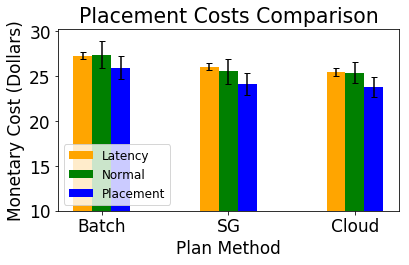

In [63]:
# Placement Cost Plot
val = 1
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

p_n_3_eb = [Batch_n_3_v[val], SG_n_3_v[val], Cloud_n_3_v[val], Myopic_n_3_v[val], Naive_n_3_v[val]]
p_n_eb = [Batch_n_v[val], SG_n_v[val], Cloud_n_v[val], Myopic_n_v[val], Naive_n_v[val]]
p_n3_eb = [Batch_3n_v[val], SG_3n_v[val], Cloud_3n_v[val], Myopic_3n_v[val], Naive_3n_v[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3[:3], yerr = p_n_3_eb[:3],
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n[:3], yerr = p_n_eb[:3],
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3[:3], yerr = p_n3_eb[:3],
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Placement Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend(loc='best', prop={'size': 12})

# Set Y axis to zero
plt.ylim(10,)

fig.tight_layout()

plt.show()

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


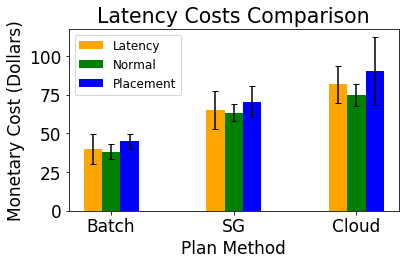

In [64]:
# Latency Cost Plot
val = 3
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

p_n_3_eb = [Batch_n_3_v[val], SG_n_3_v[val], Cloud_n_3_v[val], Myopic_n_3_v[val], Naive_n_3_v[val]]
p_n_eb = [Batch_n_v[val], SG_n_v[val], Cloud_n_v[val], Myopic_n_v[val], Naive_n_v[val]]
p_n3_eb = [Batch_3n_v[val], SG_3n_v[val], Cloud_3n_v[val], Myopic_3n_v[val], Naive_3n_v[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3[:3], yerr = p_n_3_eb[:3],
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n[:3], yerr = p_n_eb[:3],
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3[:3], yerr = p_n3_eb[:3],
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Latency Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend(loc='best', prop={'size': 12})

# Set Y axis to zero
plt.ylim(0,)

fig.tight_layout()

plt.show()

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


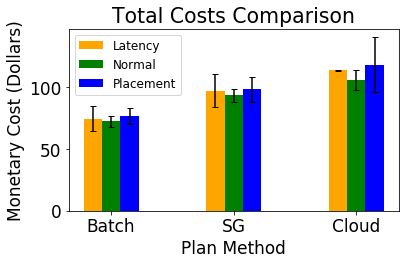

In [66]:
# Latency Cost Plot
val = 0
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

p_n_3_eb = [Batch_n_3_v[val], SG_n_3_v[val], Cloud_n_3_v[val], Myopic_n_3_v[val], Naive_n_3_v[val]]
p_n_eb = [Batch_n_v[val], SG_n_v[val], Cloud_n_v[val], Myopic_n_v[val], Naive_n_v[val]]
p_n3_eb = [Batch_3n_v[val], SG_3n_v[val], Cloud_3n_v[val], Myopic_3n_v[val], Naive_3n_v[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3[:3], yerr = p_n_3_eb[:3],
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n[:3], yerr = p_n_eb[:3],
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3[:3], yerr = p_n3_eb[:3],
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Total Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend(loc='best', prop={'size': 12})
# Set Y axis to zero
plt.ylim(0,)

fig.tight_layout()

plt.show()